# 01 — Business Analysis

Python analysis of the Olist marketplace, querying the local PostgreSQL `ecommerce` database. Monetary values are in BRL (R$).

## Data Setup

In [1]:
# Connect to the local ecommerce database
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("postgresql+psycopg://localhost/ecommerce")

In [2]:
# Shared chart style: dark theme and font for every chart in this notebook
import matplotlib.pyplot as plt

# Colour constants: change a colour here and every chart follows
BG = "#1a1a19"          # background
TEXT = "#f0efec"        # titles and key labels
TEXT_MUTED = "#c3c2b7"  # axis labels, ticks and annotations
BLUE = "#3987e5"        # main series / on time
ORANGE = "#d95926"      # problem series / late

# rcParams holds matplotlib's global settings
plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": BG,
    "savefig.facecolor": BG,
    "text.color": TEXT,
    "axes.labelcolor": TEXT_MUTED,
    "axes.edgecolor": TEXT_MUTED,
    "xtick.color": TEXT_MUTED,
    "ytick.color": TEXT_MUTED,
    "grid.color": "#383835",
    "font.family": ["Avenir Next", "Helvetica Neue", "DejaVu Sans"],  # first installed font is used
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## Order-Level Dataset

What does each order look like across payments, items and reviews?

CTEs collapse each table to one row per order before joining; `LEFT JOIN` keeps orders with no payment, items or review.

In [3]:
# One row per order: payments, items and latest review joined at order grain
order_query = """
WITH payments AS ( 
    SELECT
        order_id,
        SUM(payment_value) AS payment_value
    FROM order_payments
    GROUP BY order_id
),
items AS (
    SELECT
        order_id,
        count(*) AS item_count,
        SUM(price) AS product_value
    FROM order_items
    GROUP BY order_id
),
ranked_reviews AS (
    -- Number each order's reviews, newest first (1 = latest)
    SELECT
        order_id,
        review_score,
        ROW_NUMBER() OVER (
            PARTITION BY order_id
            ORDER BY review_creation_date DESC, review_answer_timestamp DESC
        ) AS review_rank
    FROM order_reviews
),
reviews AS (
    -- Keep only the latest review per order
    SELECT
        order_id,
        review_score
    FROM ranked_reviews
    WHERE review_rank = 1
)
SELECT
    orders.order_id,
    customers.customer_unique_id,
    customers.customer_state,
    orders.order_status,
    orders.order_purchase_timestamp,
    orders.order_delivered_customer_date,
    orders.order_estimated_delivery_date,
    payments.payment_value,
    items.item_count,
    items.product_value,
    reviews.review_score
FROM orders
JOIN customers
    ON orders.customer_id = customers.customer_id
LEFT JOIN payments
    ON orders.order_id = payments.order_id
LEFT JOIN items
    ON orders.order_id = items.order_id
LEFT JOIN reviews
    ON orders.order_id = reviews.order_id
"""

orders_df = pd.read_sql(order_query, engine)
orders_df.head()


,order_id,customer_unique_id,customer_state,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,payment_value,item_count,product_value,review_score
0,00018f77f2f0320c557190d7a144bdd3,eb28e67c4c0b83846050ddfb8a35d051,SP,delivered,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,259.83,1.0,239.90,4.0
1,000229ec398224ef6ca0657da4fc703e,3818d81c6709e39d06b2738a8d3a2474,MG,delivered,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,216.87,1.0,199.00,5.0
2,000576fe39319847cbb9d288c5617fa6,fda4476abb6307ab3c415b7e6d026526,SP,delivered,2018-07-04 12:08:27,2018-07-09 14:04:07,2018-07-25,880.75,1.0,810.00,5.0
3,0005f50442cb953dcd1d21e1fb923495,0782c41380992a5a533489063df0eef6,SP,delivered,2018-07-02 13:59:39,2018-07-04 17:28:31,2018-07-23,65.39,1.0,53.99,4.0
4,00061f2a7bc09da83e415a52dc8a4af1,107e6259485efac66428a56f10801f4f,SP,delivered,2018-03-24 22:16:10,2018-03-29 00:04:19,2018-04-09,68.87,1.0,59.99,5.0


## Delivery Performance

How early or late are orders delivered compared with the estimate?

In [4]:
# Delivery delay in days: positive = late, negative = early
delivered = orders_df["order_delivered_customer_date"]
estimated = orders_df["order_estimated_delivery_date"]

orders_df["delay_days"] = (delivered - estimated).dt.total_seconds() / 86400
orders_df["delay_days"].describe()

count    96476.000000
mean       -11.179120
std         10.186113
min       -146.016123
25%        -16.244384
50%        -11.948941
75%         -6.390000
max        188.975081
Name: delay_days, dtype: float64

In [5]:
# Delivery status, same definition as sql/analysis.sql
orders_df["delivery_status"] = "Not Delivered"
orders_df.loc[delivered.notna() & (delivered <= estimated), "delivery_status"] = "On Time"
orders_df.loc[delivered.notna() & (delivered > estimated), "delivery_status"] = "Late"

orders_df["delivery_status"].value_counts()

delivery_status
On Time          88649
Late              7827
Not Delivered     2965
Name: count, dtype: int64

### Delay Distribution

Are late orders slightly late or very late, and how early do most orders arrive?

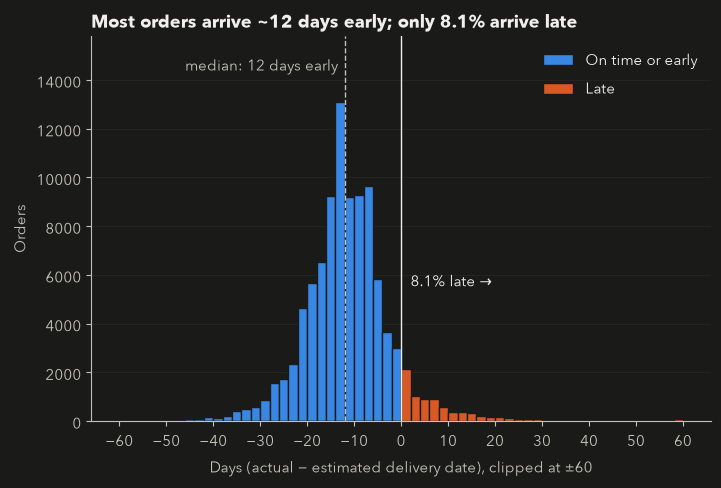

In [6]:
# Histogram of delivery delay, delivered orders only
delivered_delay = orders_df.loc[orders_df["delivery_status"] != "Not Delivered", "delay_days"]

# Numbers for the title and annotations, calculated from the data
median_delay = delivered_delay.median()
late_share = (delivered_delay > 0).mean() * 100

fig, ax = plt.subplots(figsize=(8, 5))

# Early/on-time in blue, late in orange; shared 2-day bins keep the bars aligned
bins = range(-60, 62, 2)
clipped_delay = delivered_delay.clip(-60, 60)  # clipped for the chart only
ax.hist(clipped_delay[delivered_delay <= 0], bins=bins, color=BLUE, edgecolor=BG, label="On time or early")
ax.hist(clipped_delay[delivered_delay > 0], bins=bins, color=ORANGE, edgecolor=BG, label="Late")

# Reference lines and annotations
ax.set_ylim(top=ax.get_ylim()[1] * 1.15)  # headroom above the bars for the labels
ax.axvline(0, color=TEXT, linewidth=1)  # the estimated delivery date
ax.axvline(median_delay, color=TEXT_MUTED, linewidth=1, linestyle="--")
ax.text(median_delay - 1.5, ax.get_ylim()[1] * 0.95, f"median: {abs(median_delay):.0f} days early",
        ha="right", va="top", color=TEXT_MUTED)
ax.text(2, ax.get_ylim()[1] * 0.35, f"{late_share:.1f}% late →", ha="left", color=TEXT)

ax.set_title(f"Most orders arrive ~{abs(median_delay):.0f} days early; only {late_share:.1f}% arrive late",
             loc="left", fontsize=13)
ax.set_xlabel("Days (actual − estimated delivery date), clipped at ±60")
ax.set_ylabel("Orders")
ax.set_xticks(range(-60, 61, 10))
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)  # gridlines behind the bars
ax.legend(frameon=False)

plt.show()

**Finding**

- Most delivered orders arrive well before the estimate: the median is about **12 days early**, and only **8.1%** (7,827 of 96,476) arrive late.
- Late orders are mostly a few days late, with a thin tail of very late ones.
- The estimates look conservative. That keeps the late rate low, but a long promised delivery time may put some customers off at checkout (a hypothesis this data can't test).

### Review Scores: Late vs On Time

Do late orders get worse reviews, and how does the full score distribution differ?

delivery_status  Late  On Time
review_score                  
1.0              46.2      6.6
2.0               7.8      2.6
3.0              11.4      8.0
4.0              12.3     20.4
5.0              22.2     62.4


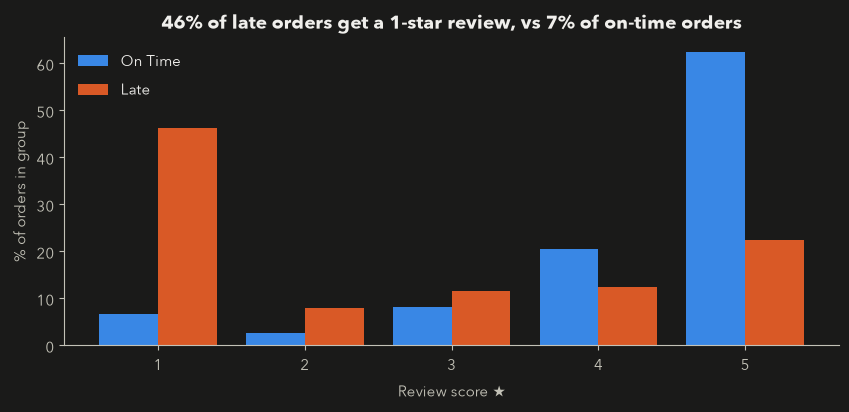

In [7]:
# Review score distribution by delivery status (% within each group)
reviewed = orders_df[(orders_df["delivery_status"] != "Not Delivered") & (orders_df["review_score"].notna())]

# Rows = review score, columns = delivery status; each column adds up to 100%
shares = pd.crosstab(reviewed["review_score"], reviewed["delivery_status"], normalize="columns") * 100
print(shares.round(1))

# 1-star shares for the title
late_1star = shares.loc[1, "Late"]
ontime_1star = shares.loc[1, "On Time"]

# Grouped bars: one On Time / Late pair per score
fig, ax = plt.subplots(figsize=(10, 4))
x = range(len(shares))
width = 0.4
ax.bar([i - width / 2 for i in x], shares["On Time"], width, color=BLUE, label="On Time")
ax.bar([i + width / 2 for i in x], shares["Late"], width, color=ORANGE, label="Late")

ax.set_xticks(list(x))
ax.set_xticklabels(shares.index.astype(int))  # show 1-5 instead of 1.0-5.0
ax.set_xlabel("Review score ★")
ax.set_ylabel("% of orders in group")
ax.set_title(f"{late_1star:.0f}% of late orders get a 1-star review, vs {ontime_1star:.0f}% of on-time orders",
             loc="center")
ax.legend(frameon=False)

plt.show()

**Finding**

- Late orders are far more likely to get the lowest score: **46%** of late orders get 1 star, vs **7%** of on-time orders.
- On-time orders cluster at the top: **62%** give 5 stars, vs **22%** of late orders.
- Each order uses its **latest** review, so every score is one a customer actually gave.
- This is an association, not proof that lateness causes low scores.

## Product Categories

Which product categories generate the most product sales?

Sales = `SUM(price)` (product value excluding freight). Grain: one row per order item.

In [8]:
# Item-level data: one row per order item, with its English category name
items_query = """
SELECT
    order_items.order_id,
    COALESCE(
        product_category_name_translation.product_category_name_english,
        products.product_category_name,
        'uncategorized'
    ) AS category,
    order_items.price,
    order_items.freight_value
FROM order_items
JOIN products
    ON order_items.product_id = products.product_id
LEFT JOIN product_category_name_translation
    ON products.product_category_name = product_category_name_translation.product_category_name
"""

items_df = pd.read_sql(items_query, engine)
items_df.shape  # expect (112650, 4): one row per order item, none lost


(112650, 4)

                            sales  items_sold
category                                     
health_beauty          1258681.34        9670
watches_gifts          1205005.68        5991
bed_bath_table         1036988.68       11115
sports_leisure          988048.97        8641
computers_accessories   911954.32        7827
furniture_decor         729762.49        8334
cool_stuff              635290.85        3796
housewares              632248.66        6964
auto                    592720.11        4235
garden_tools            485256.46        4347


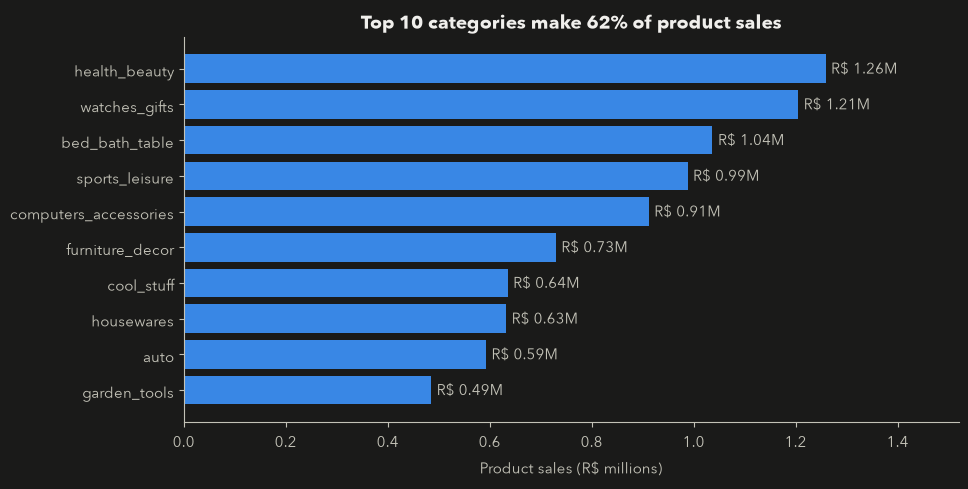

In [9]:
# Top 10 categories by product sales (price, excluding freight)
top = (items_df.groupby("category")
            .agg(sales=("price", "sum"), items_sold=("price", "count"))
            .sort_values("sales", ascending=False)
            .head(10))

# Share of all product sales that the top 10 represent
top_share = top["sales"].sum() / items_df["price"].sum() * 100
print(top)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(top.index, top["sales"] / 1_000_000, color=BLUE)  # bar lengths in R$ millions
ax.invert_yaxis()  # barh draws the first row at the bottom; flip it so the biggest is on top

# Value labels, with headroom on the right so the longest one fits
ax.bar_label(bars, labels=[f"R$ {v:.2f}M" for v in top["sales"] / 1_000_000], padding=4, color=TEXT_MUTED)
ax.set_xlim(right=ax.get_xlim()[1] * 1.15)

ax.set_xlabel("Product sales (R$ millions)")
ax.set_title(f"Top 10 categories make {top_share:.0f}% of product sales")

plt.show()

**Finding**

- The top 10 of 74 categories make up **62%** of product sales (R$8.5M of R$13.6M).
- Higher sales don't always mean more items sold: `watches_gifts` sells fewer items than `bed_bath_table` but earns more, because each item costs more.
- Items with no category (1.3% of sales) are kept as "uncategorized". They rank 21st, outside the top 10.

## Satisfaction by Category

Do the top-selling categories also earn good reviews?

Grain: one row per (order, category). Each order carries its latest review score.

In [10]:
# Average review score per category, top 10 by sales; one row per (order, category)

# Orders that have a review, with their latest score
reviews_by_order = orders_df.loc[orders_df["review_score"].notna(), ["order_id", "review_score"]]

# One row per (order, category): an order with 3 items in one category counts once
order_categories = items_df[["order_id", "category"]].drop_duplicates()
order_categories = order_categories[order_categories["category"].isin(top.index)]

# Join reviews onto order_categories by order_id; inner = keep orders found in both tables
merged = order_categories.merge(reviews_by_order, on="order_id", how="inner")

satisfaction = (merged.groupby("category")
                      .agg(orders=("order_id", "count"), avg_review=("review_score", "mean"))
                      .sort_values("avg_review"))
print(satisfaction)


                       orders  avg_review
category                                 
bed_bath_table           9313    3.969827
furniture_decor          6398    4.009222
computers_accessories    6649    4.025568
watches_gifts            5576    4.065459
auto                     3877    4.089244
garden_tools             3496    4.135584
housewares               5843    4.140852
sports_leisure           7669    4.167167
cool_stuff               3599    4.170325
health_beauty            8771    4.180937


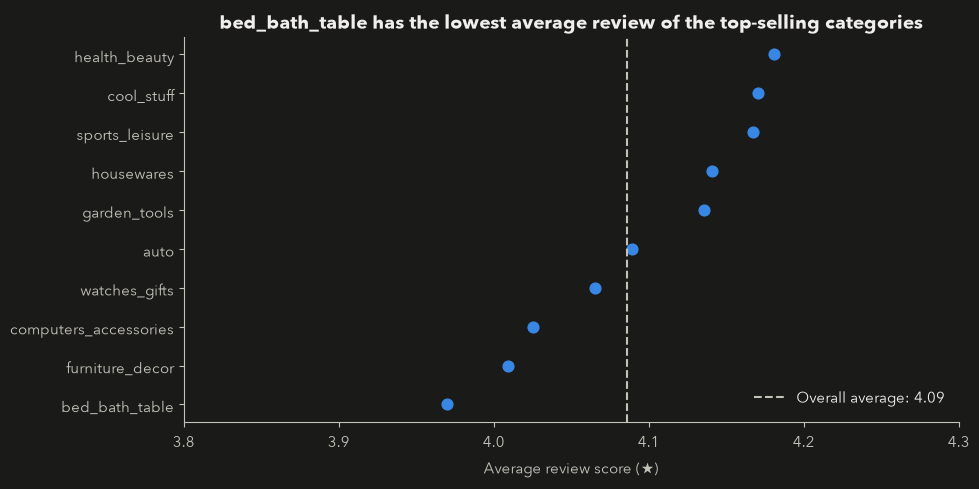

In [11]:
# Average review score for the top 10 sales categories (dot plot)

# 1. Overall average review score, as a reference line
overall = reviews_by_order["review_score"].mean()

# 2. Figure and dots: score on the x-axis, category on the y-axis
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(satisfaction["avg_review"], satisfaction.index, color=BLUE, s=60)

# 3. Reference line (labelled in the legend), x-axis range and labels
ax.axvline(overall, color=TEXT_MUTED, linestyle="--", label=f"Overall average: {overall:.2f}")
ax.set_xlim(3.8, 4.3)  # zoomed axis: fine for dots (position), not for bars (length)
ax.set_xlabel("Average review score (★)")
ax.legend(frameon=False, loc="lower right")

# 4. Action title, using the lowest category (calculated)
lowest = satisfaction.index[0]
ax.set_title(f"{lowest} has the lowest average review of the top-selling categories")

# 5. Show the chart
plt.show()


**Finding**

- `bed_bath_table` has the lowest average review of the top 10 categories by sales (**3.97**), about 0.12 stars below the overall average (4.09). It also has the most orders of the ten (9,313), though not the most sales.
- The highest-sales category, `health_beauty`, is also the best rated (**4.18**).
- The whole spread is only about 0.2 stars, so this is a mild gap, not widespread dissatisfaction. The data doesn't show why.

## Seller Concentration

Do a few sellers generate most of the sales?

Sales = `SUM(price)` per seller. Grain: one row per seller.

In [12]:
# Product sales per seller
seller_query = """
SELECT
    seller_id,
    SUM(price) AS sales
FROM order_items
GROUP BY seller_id
"""

seller_sales = pd.read_sql(seller_query, engine)
seller_sales.shape  # expect (3095, 2): one row per seller


(3095, 2)

In [13]:
# Seller concentration: rank sellers by sales, then take the running total of their share
seller_sales = seller_sales.sort_values("sales", ascending=False).reset_index(drop=True)
seller_sales["share"] = seller_sales["sales"] / seller_sales["sales"].sum()
seller_sales["cum_share"] = seller_sales["share"].cumsum()
seller_sales["seller_pct"] = (seller_sales.index + 1) / len(seller_sales)

# Share of all sales made by the top 20% of sellers
top20_share = seller_sales.loc[seller_sales["seller_pct"] <= 0.2, "share"].sum()
print(f"Top 20% of sellers make {top20_share:.1%} of sales")


Top 20% of sellers make 82.7% of sales


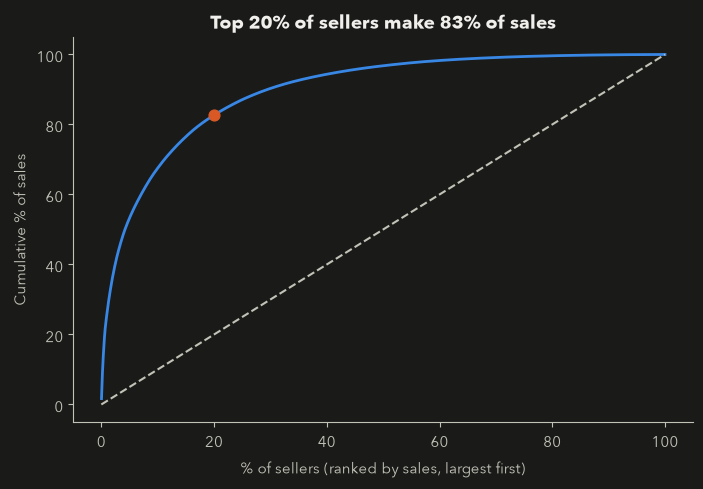

In [14]:
# Cumulative share of sales vs share of sellers (Pareto curve)

# 1. Figure and the cumulative curve (x and y as percentages)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(seller_sales["seller_pct"] * 100, seller_sales["cum_share"] * 100, color=BLUE, linewidth=2)

# 2. Equal-share reference line (dashed diagonal)
ax.plot([0, 100], [0, 100], color=TEXT_MUTED, linestyle="--")

# 3. Mark the top 20% of sellers
ax.scatter(20, top20_share * 100, color=ORANGE, s=60, zorder=3)

# 4. Labels and action title (use top20_share, calculated)
ax.set_xlabel("% of sellers (ranked by sales, largest first)")
ax.set_ylabel("Cumulative % of sales")
ax.set_title(f"Top 20% of sellers make {top20_share:.0%} of sales")

# 5. Show the chart
plt.show()


In [15]:
# Number of sellers needed to reach half of all sales
# cum_share is below the threshold for every seller before the one that crosses it
sellers_for_half = (seller_sales["cum_share"] < 0.5).sum() + 1
print(f"{sellers_for_half} of {len(seller_sales)} sellers make half of all sales")


130 of 3095 sellers make half of all sales


**Finding**

- Sales are concentrated: the top 20% of sellers make about **83%** of product sales, in line with the 80/20 rule.
- Just **130 of 3,095 sellers** (about 4%) make half of all sales.
- The marketplace depends on a small group of sellers, a concentration risk, while most sellers are small.